# Beginner Project: Retail Sales Data Analysis

**Goal:** Analyze one year of fictional retail orders using **Python, pandas, and Matplotlib**. This is a full beginner portfolio project: load data → inspect → clean → analyze → visualize → report findings.

> **Important:** The dataset is **synthetic (generated for practice)**. It does not represent sales from any real business.

### Business questions
1. How much revenue did the store earn in 2025?
2. Which product categories and products generated the most revenue?
3. Which cities contributed the most revenue?
4. How did revenue change month to month?
5. Which payment method was most common?

**How to use:** Put this notebook and `retail_sales.csv` in the same folder. Run all cells from top to bottom. The figures will be saved in `charts/`.

## Step 1 — Import libraries

- **pandas** reads and analyzes tables (DataFrames).
- **matplotlib** produces charts.
- **Path** helps find files and make output folders.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option('display.max_columns', 20)
Path('charts').mkdir(exist_ok=True)
plt.rcParams['figure.figsize'] = (9, 5)

## Step 2 — Load the CSV file

A **CSV** is a plain-text spreadsheet-like file. `pd.read_csv()` loads it into a **DataFrame**, a table of rows and columns.

In [2]:
df = pd.read_csv('retail_sales.csv')
print('Rows and columns (raw):', df.shape)
display(df.head())

Rows and columns (raw): (1012, 9)


,Order_ID,Order_Date,City,Category,Product,Quantity,Unit_Price_INR,Discount_Pct,Payment_Method
0,ORD-0925,2025-09-01,Kolkata,Clothing,Jacket,1,2099,5.0,Cash on Delivery
1,ORD-0364,2025-11-11,Bengaluru,Home & Kitchen,Coffee Mug,1,280,0.0,Credit/Debit Card
2,ORD-0893,2025-04-07,Bengaluru,Beauty,Body Lotion,1,424,10.0,Credit/Debit Card
3,ORD-0043,2025-05-07,Delhi,Home & Kitchen,Bedsheet,2,1088,0.0,UPI
4,ORD-0450,2025-12-25,Bengaluru,Grocery,Cooking Oil,2,176,0.0,UPI


## Step 3 — Explore data quality

Before analysis, check data types, missing values, and duplicate rows. These checks prevent misleading results.

In [3]:
print('Column types:')
print(df.dtypes)
print(); print('Missing values per column:')
print(df.isna().sum())
print(); print('Duplicate rows:', df.duplicated().sum())

Column types:
Order_ID           object
Order_Date         object
City               object
Category           object
Product            object
Quantity            int64
Unit_Price_INR      int64
Discount_Pct      float64
Payment_Method     object
dtype: object

Missing values per column:
Order_ID           0
Order_Date         0
City              14
Category           0
Product            0
Quantity           0
Unit_Price_INR     0
Discount_Pct       9
Payment_Method     0
dtype: int64

Duplicate rows: 12


## Step 4 — Clean the dataset

1. Remove exact duplicate rows so an order is not counted twice.
2. Convert the date column into a date type.
3. Label missing cities as **Unknown** instead of silently removing purchases.
4. Fill missing discounts with **0%** for this *practice dataset* (an assumption, not always appropriate in real business data).
5. Keep only orders with valid dates, positive quantities/prices, and discounts between 0% and 100%.

**Important:** In a real dataset, first verify why values are missing with the business owner.

In [4]:
before = len(df)
df = df.drop_duplicates().copy()
df['Order_Date'] = pd.to_datetime(df['Order_Date'], errors='coerce')
df['City'] = df['City'].fillna('Unknown')
df['Discount_Pct'] = pd.to_numeric(df['Discount_Pct'], errors='coerce').fillna(0)
df['Quantity'] = pd.to_numeric(df['Quantity'], errors='coerce')
df['Unit_Price_INR'] = pd.to_numeric(df['Unit_Price_INR'], errors='coerce')
df = df.dropna(subset=['Order_Date', 'Quantity', 'Unit_Price_INR'])
df = df[
    (df['Quantity'] > 0) &
    (df['Unit_Price_INR'] > 0) &
    df['Discount_Pct'].between(0, 100)
].copy()
print('Removed rows:', before - len(df))
print('Clean orders:', len(df))
print('Missing values after cleaning:', df.isna().sum().sum())

Removed rows: 12
Clean orders: 1000
Missing values after cleaning: 0


## Step 5 — Create useful columns

**Sales revenue** = quantity × unit price × (1 − discount/100).

For example, 2 shirts priced at ₹500 each with a 10% discount earn **₹900** in revenue. Add month labels to study trends.

In [5]:
df['Revenue_INR'] = (
    df['Quantity'] * df['Unit_Price_INR'] * (1 - df['Discount_Pct'] / 100)
).round(2)
df['Month'] = df['Order_Date'].dt.to_period('M').astype(str)
display(df[['Order_ID', 'Quantity', 'Unit_Price_INR', 'Discount_Pct', 'Revenue_INR', 'Month']].head())

,Order_ID,Quantity,Unit_Price_INR,Discount_Pct,Revenue_INR,Month
0,ORD-0925,1,2099,5.0,1994.05,2025-09
1,ORD-0364,1,280,0.0,280.00,2025-11
2,ORD-0893,1,424,10.0,381.60,2025-04
3,ORD-0043,2,1088,0.0,2176.00,2025-05
4,ORD-0450,2,176,0.0,352.00,2025-12


## Step 6 — Calculate KPIs

A **KPI** (key performance indicator) is a number that summarizes business performance.

- **Total revenue:** Sum of all sales after discount.
- **Orders:** Count of unique order IDs.
- **Average order value (AOV):** Total revenue ÷ number of orders.
- **Units sold:** Total quantity sold.

In [6]:
total_revenue = df['Revenue_INR'].sum()
order_count = df['Order_ID'].nunique()
units_sold = df['Quantity'].sum()
aov = total_revenue / order_count
print(f'Total revenue: ₹{total_revenue:,.2f}')
print(f'Unique orders: {order_count:,}')
print(f'Units sold: {units_sold:,}')
print(f'Average order value: ₹{aov:,.2f}')

Total revenue: ₹1,274,490.40
Unique orders: 1,000
Units sold: 1,529
Average order value: ₹1,274.49


## Step 7 — Revenue by category

`groupby()` combines rows with the same category. `sum()` adds their revenue, and `sort_values()` ranks them.

Category
Clothing          558537.75
Electronics       375969.40
Home & Kitchen    173261.40
Beauty             84009.65
Grocery            82712.20


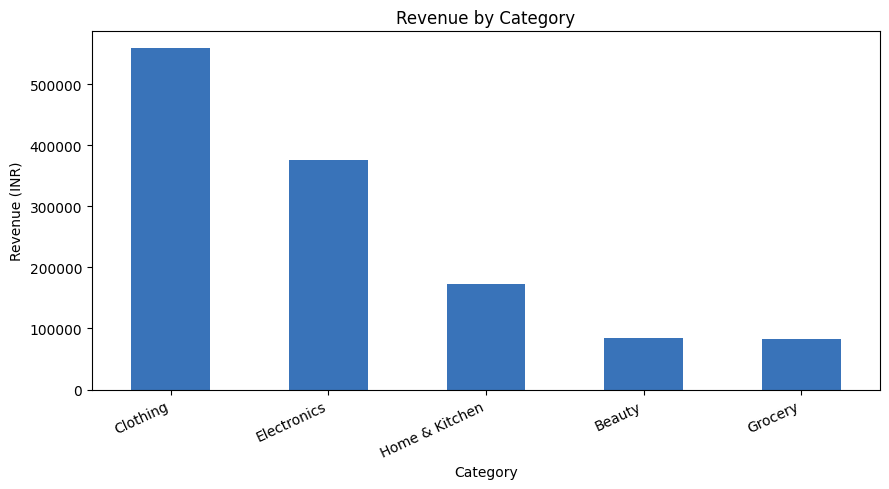

In [7]:
category_sales = df.groupby('Category')['Revenue_INR'].sum().sort_values(ascending=False)
print(category_sales.round(2).to_string())
ax = category_sales.plot(kind='bar', color='#3973b9')
ax.set(title='Revenue by Category', xlabel='Category', ylabel='Revenue (INR)')
plt.xticks(rotation=25, ha='right')
plt.tight_layout()
plt.savefig('charts/01_category_revenue.png', dpi=150)
plt.show()

## Step 8 — Monthly sales trend

A line chart helps spot increases, decreases, and seasonal patterns.

Month
2025-01     93532.50
2025-02     82728.55
2025-03     82330.60
2025-04     55823.25
2025-05    117713.05
2025-06     73502.80
2025-07     88667.40
2025-08    113483.20
2025-09    113239.90
2025-10    199855.50
2025-11    147087.20
2025-12    106526.45


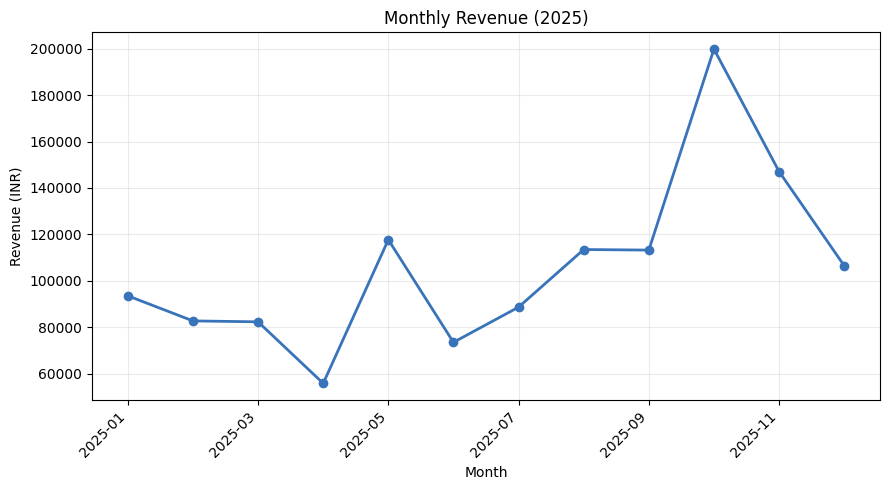

In [8]:
monthly_sales = df.groupby('Month')['Revenue_INR'].sum().sort_index()
print(monthly_sales.round(2).to_string())
ax = monthly_sales.plot(kind='line', marker='o', linewidth=2, color='#3973b9')
ax.set(title='Monthly Revenue (2025)', xlabel='Month', ylabel='Revenue (INR)')
plt.xticks(rotation=45, ha='right')
plt.grid(alpha=.25)
plt.tight_layout()
plt.savefig('charts/02_monthly_revenue.png', dpi=150)
plt.show()

## Step 9 — Revenue by city

A horizontal bar chart makes it easy to compare city names. The **Unknown** group contains orders with missing city data.

City
Delhi        272017.75
Mumbai       258216.40
Bengaluru    225727.30
Hyderabad    193393.05
Kolkata      160896.20
Pune         147737.85
Unknown       16501.85


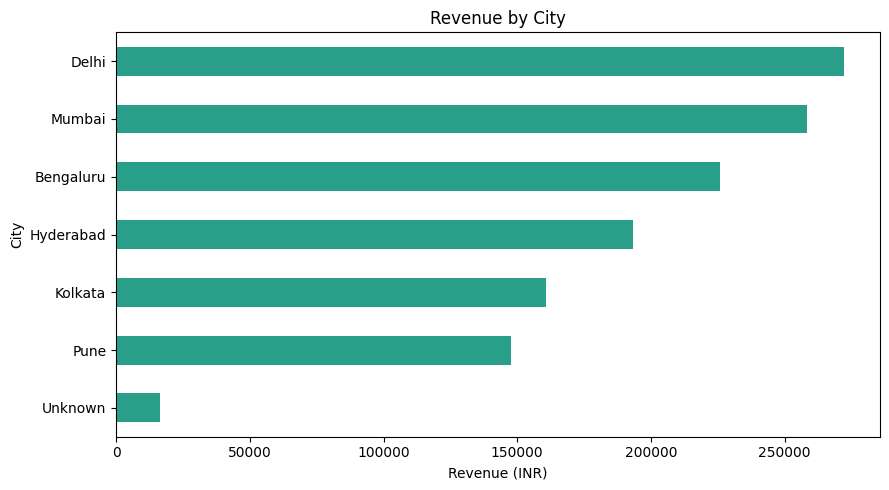

In [9]:
city_sales = df.groupby('City')['Revenue_INR'].sum().sort_values(ascending=False)
print(city_sales.round(2).to_string())
ax = city_sales.sort_values().plot(kind='barh', color='#299e88')
ax.set(title='Revenue by City', xlabel='Revenue (INR)', ylabel='City')
plt.tight_layout()
plt.savefig('charts/03_city_revenue.png', dpi=150)
plt.show()

## Step 10 — Best-selling products

**Revenue** and **quantity** answer different questions. Here we rank products by revenue; an expensive product may outrank a popular cheaper one.

Product
Jacket               223866.95
Sneakers             193635.35
Bluetooth Speaker    151541.20
Headphones           126276.90
Jeans                 93946.00
Bedsheet              82677.40
Power Bank            78167.45


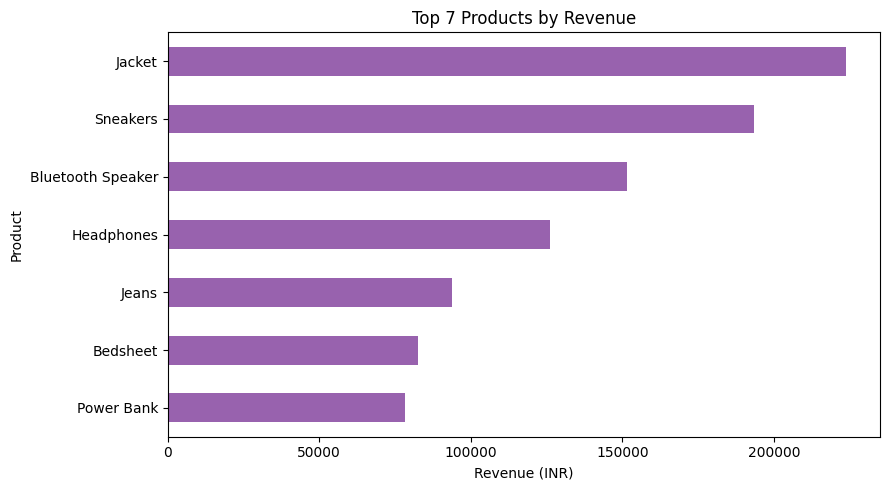

In [10]:
product_sales = df.groupby('Product')['Revenue_INR'].sum().nlargest(7)
print(product_sales.round(2).to_string())
ax = product_sales.sort_values().plot(kind='barh', color='#9862ae')
ax.set(title='Top 7 Products by Revenue', xlabel='Revenue (INR)', ylabel='Product')
plt.tight_layout()
plt.savefig('charts/04_top_products.png', dpi=150)
plt.show()

## Step 11 — Payment method usage

`value_counts()` counts how often a method appears. This answers **transaction frequency**, not revenue share.

Payment_Method
UPI                  426
Credit/Debit Card    315
Cash on Delivery     189
Net Banking           70


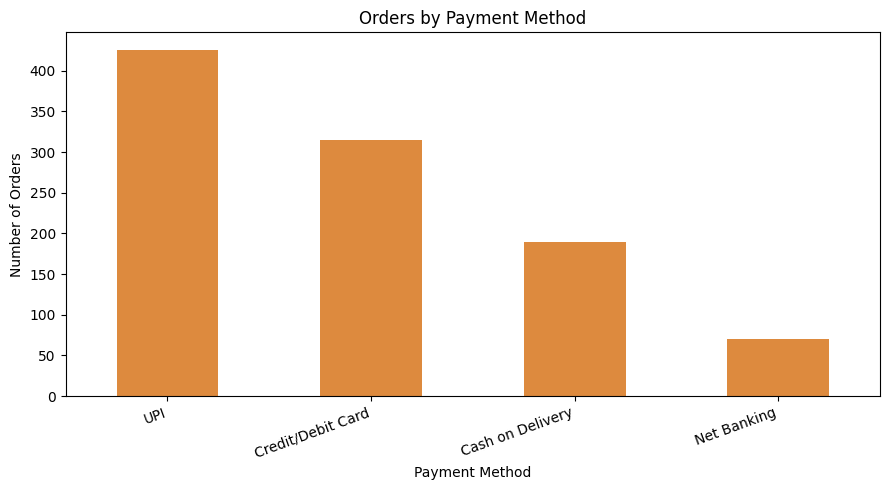

In [11]:
payment_counts = df['Payment_Method'].value_counts()
print(payment_counts.to_string())
ax = payment_counts.plot(kind='bar', color='#dd8a3e')
ax.set(title='Orders by Payment Method', xlabel='Payment Method', ylabel='Number of Orders')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.savefig('charts/05_payment_methods.png', dpi=150)
plt.show()

## Step 12 — Summarize findings

Turn calculations into clear business language. The answers below are **generated directly from the cleaned data**; they are not guesses.

In [12]:
peak_month = monthly_sales.idxmax()
top_category = category_sales.idxmax()
top_city = city_sales.drop(labels='Unknown', errors='ignore').idxmax()
top_product = product_sales.idxmax()
top_payment = payment_counts.idxmax()

findings = f"""# Retail Sales Analysis — Findings

**Dataset:** Synthetic educational data, calendar year 2025.
**Cleaning:** Removed {before - len(df)} duplicate/invalid rows, labelled missing cities Unknown, and assumed a 0% discount where missing.

## Key metrics
- Total revenue: ₹{total_revenue:,.2f}
- Unique orders: {order_count:,}
- Units sold: {units_sold:,}
- Average order value: ₹{aov:,.2f}

## Main findings
1. **Top category:** {top_category} (₹{category_sales.iloc[0]:,.2f}).
2. **Peak month:** {peak_month} (₹{monthly_sales.max():,.2f}).
3. **Top known city:** {top_city} (₹{city_sales[top_city]:,.2f}).
4. **Top product by revenue:** {top_product} (₹{product_sales.iloc[0]:,.2f}).
5. **Most-used payment method:** {top_payment} ({payment_counts.iloc[0]:,} orders).

## Possible business actions (hypotheses, not proven conclusions)
- Review inventory for high-revenue categories and products.
- Investigate what caused the peak month before planning promotions.
- Monitor data-entry quality to reduce Unknown city entries.

## Limitations
- The dataset is artificial and designed for learning. Results are not evidence about a real company.
- There is no profit, customer, return, or marketing-spend data; revenue alone does not indicate profitability.
"""
Path('findings.md').write_text(findings, encoding='utf-8')
print(findings)

# Retail Sales Analysis — Findings

**Dataset:** Synthetic educational data, calendar year 2025.
**Cleaning:** Removed 12 duplicate/invalid rows, labelled missing cities Unknown, and assumed a 0% discount where missing.

## Key metrics
- Total revenue: ₹1,274,490.40
- Unique orders: 1,000
- Units sold: 1,529
- Average order value: ₹1,274.49

## Main findings
1. **Top category:** Clothing (₹558,537.75).
2. **Peak month:** 2025-10 (₹199,855.50).
3. **Top known city:** Delhi (₹272,017.75).
4. **Top product by revenue:** Jacket (₹223,866.95).
5. **Most-used payment method:** UPI (426 orders).

## Possible business actions (hypotheses, not proven conclusions)
- Review inventory for high-revenue categories and products.
- Investigate what caused the peak month before planning promotions.
- Monitor data-entry quality to reduce Unknown city entries.

## Limitations
- The dataset is artificial and designed for learning. Results are not evidence about a real company.
- There is no profit, custom

## Step 13 — Practice challenges (try them yourself)

1. Find the **top 5 products by quantity**, not revenue.
2. Calculate average revenue per transaction for each city.
3. Filter to **October** and find the highest-revenue category.
4. Calculate how many orders received a discount greater than 0%.
5. **Bonus:** Make a bar chart showing orders by weekday.

### Interview / portfolio explanation

> “I analyzed 1,000 synthetic retail orders using Python and pandas. I cleaned duplicate records and missing values, calculated revenue and average order value, used groupby operations to compare categories and locations, and created five Matplotlib charts. I summarized the results and noted the limitations of synthetic data.”

**Tip:** Once you understand this project, replace `retail_sales.csv` with a public real-world dataset and clearly credit its source. That makes a stronger portfolio project.